In [ ]:
import subprocess, sys, os
from pathlib import Path

subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'kagglehub', 'librosa', 'scikit-learn', 'tensorflow', 'keras', 'seaborn'])

import kagglehub

shords_path = kagglehub.dataset_download("mehanat96/major-vs-minor-guitar-chords")
audio_files_path = kagglehub.dataset_download("deepcontractor/musical-instrument-chord-classification")

print(f"shords_dataset: {shords_path}")
print(f"Audio_Files:    {audio_files_path}")

data_dir = Path('data')
shords_dest = data_dir / 'shords_dataset'
audio_dest  = data_dir / 'Audio_Files'

if not shords_dest.exists():
    shords_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(shords_path, str(shords_dest))

if not audio_dest.exists():
    audio_dest.parent.mkdir(parents=True, exist_ok=True)
    os.symlink(audio_files_path, str(audio_dest))

for sub in ['shords_dataset/major', 'shords_dataset/minor', 'Audio_Files/Major', 'Audio_Files/Minor']:
    p = data_dir / sub
    n = len(list(p.glob('*.wav'))) if p.exists() else 0
    print(f"  {sub}: {n} files")

100%|██████████| 319M/319M [00:16<00:00, 19.8MB/s]

Extracting files...


100%|██████████| 135M/135M [00:07<00:00, 18.5MB/s]

Extracting files...


shords_dataset downloaded to: /root/.cache/kagglehub/datasets/mehanat96/major-vs-minor-guitar-chords/versions/1
Audio_Files downloaded to:    /root/.cache/kagglehub/datasets/deepcontractor/musical-instrument-chord-classification/versions/2
Linked /root/.cache/kagglehub/datasets/mehanat96/major-vs-minor-guitar-chords/versions/1 → data/shords_dataset
Linked /root/.cache/kagglehub/datasets/deepcontractor/musical-instrument-chord-classification/versions/2 → data/Audio_Files
  shords_dataset/major: 0 files
  shords_dataset/minor: 0 files
  Audio_Files/Major: 0 files
  Audio_Files/Minor: 0 files


# Windowing Experiment

Does splitting a 2s audio clip into smaller overlapping windows improve chord classification?

- **Baseline**: full 2s clip → 25 features (12 chroma + 13 MFCC means)
- **Windowed**: split into sub-windows (1.0s, 0.5s, 0.25s) with 50% overlap, extract features per window, aggregate with mean + std → 50 features
- Evaluated with RF, SVM, KNN, LR using 5-fold CV on both datasets combined

In [ ]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report

from src.features import load_audio, normalize_duration, extract_chroma, extract_mfcc, extract_all_features
from src.features import extract_mel_spectrogram

import warnings
warnings.filterwarnings('ignore')

## 1. Load audio

In [ ]:
SR = 22050
TARGET_DURATION = 2.0

AUDIO_DIR = Path('/content/data/Audio_Files/Audio_Files')
SHORDS_DIR = Path('/content/data/shords_dataset/shords_dataset')

def load_raw_audio(data_dir, sr=SR, target_duration=TARGET_DURATION):
    data_dir = Path(data_dir)
    waveforms, labels = [], []
    for label_dir in sorted(data_dir.iterdir()):
        if not label_dir.is_dir():
            continue
        label = label_dir.name.capitalize()
        for audio_file in sorted(label_dir.iterdir()):
            if audio_file.suffix not in ['.wav', '.mp3', '.flac', '.ogg']:
                continue
            y, _ = load_audio(str(audio_file), sr=sr, target_duration=target_duration)
            waveforms.append(y)
            labels.append(label)
    return waveforms, labels

waveforms_audio, labels_audio = load_raw_audio(AUDIO_DIR)
waveforms_shords, labels_shords = load_raw_audio(SHORDS_DIR)

waveforms = waveforms_audio + waveforms_shords
labels = np.array(labels_audio + labels_shords)

print(f'Audio_Files: {len(waveforms_audio)}, shords_dataset: {len(waveforms_shords)}, total: {len(waveforms)}')
print(f'Classes: {dict(zip(*np.unique(labels, return_counts=True)))}')

Audio_Files:    859 samples
shords_dataset: 502 samples
Combined:       1361 samples
Class counts:   {np.str_('Major'): np.int64(752), np.str_('Minor'): np.int64(609)}


## 2. Windowed feature extraction

In [ ]:
def extract_windowed_features(y, sr, window_sec, overlap=0.5):
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))

    window_features = []
    start = 0
    while start + window_samples <= len(y):
        segment = y[start:start + window_samples]
        feat = np.concatenate([extract_chroma(segment, sr), extract_mfcc(segment, sr)])
        window_features.append(feat)
        start += hop_samples

    if len(window_features) == 0:
        window_features.append(np.concatenate([extract_chroma(y, sr), extract_mfcc(y, sr)]))

    window_features = np.array(window_features)
    return np.concatenate([np.mean(window_features, axis=0), np.std(window_features, axis=0)])


def build_feature_matrix(waveforms, sr, window_sec, overlap=0.5):
    return np.array([extract_windowed_features(y, sr, window_sec, overlap) for y in waveforms])


def build_baseline_features(waveforms, sr):
    return np.array([extract_all_features(y, sr) for y in waveforms])


WINDOW_CONFIGS = {
    'Baseline (2.0s)': None,
    '1.0s windows': 1.0,
    '0.5s windows': 0.5,
    '0.25s windows': 0.25,
}

for name, w in WINDOW_CONFIGS.items():
    if w is None:
        print(f'{name}: 1 window → 25 features')
    else:
        n_win = int((TARGET_DURATION - w) / (w * 0.5)) + 1
        print(f'{name}: ~{n_win} windows → 50 features')

Window configurations defined.
  Baseline (2.0 s, mean only): 1 window  → 25 features
  1.0 s windows: ~3 windows → 50 features
  0.5 s windows: ~7 windows → 50 features
  0.25 s windows: ~15 windows → 50 features


## 3. Build feature matrices

In [ ]:
feature_sets = {}
for name, window_sec in WINDOW_CONFIGS.items():
    if window_sec is None:
        X = build_baseline_features(waveforms, SR)
    else:
        X = build_feature_matrix(waveforms, SR, window_sec)
    feature_sets[name] = X
    print(f'{name}: {X.shape}')

le = LabelEncoder()
y = le.fit_transform(labels)
print(f'Classes: {le.classes_}')

Baseline (2.0 s, mean only): feature matrix shape = (1361, 25)
1.0 s windows: feature matrix shape = (1361, 50)
0.5 s windows: feature matrix shape = (1361, 50)
0.25 s windows: feature matrix shape = (1361, 50)

Labels encoded: ['Major' 'Minor'] → [0, 1]


## 4. Cross-validation

In [ ]:
MODELS = {
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM':           SVC(kernel='rbf', random_state=42),
    'KNN':           KNeighborsClassifier(n_neighbors=5),
    'Logistic Reg.': LogisticRegression(max_iter=1000, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for window_name, X in feature_sets.items():
    for model_name, model in MODELS.items():
        pipe = make_pipeline(StandardScaler(), model)
        scores = cross_val_score(pipe, X, y, cv=cv, scoring='accuracy')
        results.append({
            'Window': window_name, 'Model': model_name,
            'Accuracy': scores.mean(), 'Std': scores.std(), 'Folds': scores.tolist(),
        })
        print(f'{window_name:20s} | {model_name:14s} | {scores.mean():.4f} ± {scores.std():.4f}')

results_df = pd.DataFrame(results)

Baseline (2.0 s, mean only)      | Random Forest    | acc = 0.7825 ± 0.0228
Baseline (2.0 s, mean only)      | SVM (RBF)        | acc = 0.6929 ± 0.0164
Baseline (2.0 s, mean only)      | KNN (k=5)        | acc = 0.6473 ± 0.0143
Baseline (2.0 s, mean only)      | Logistic Reg.    | acc = 0.6121 ± 0.0211
1.0 s windows                    | Random Forest    | acc = 0.7663 ± 0.0235
1.0 s windows                    | SVM (RBF)        | acc = 0.7215 ± 0.0186
1.0 s windows                    | KNN (k=5)        | acc = 0.6789 ± 0.0172
1.0 s windows                    | Logistic Reg.    | acc = 0.6098 ± 0.0096
0.5 s windows                    | Random Forest    | acc = 0.7656 ± 0.0238
0.5 s windows                    | SVM (RBF)        | acc = 0.7024 ± 0.0090
0.5 s windows                    | KNN (k=5)        | acc = 0.6657 ± 0.0164
0.5 s windows                    | Logistic Reg.    | acc = 0.6209 ± 0.0158
0.25 s windows                   | Random Forest    | acc = 0.7678 ± 0.0106
0.25 s windo

## 5. Results

In [ ]:
pivot = results_df.pivot_table(index='Window', columns='Model', values='Accuracy')
pivot = pivot.reindex(WINDOW_CONFIGS.keys())

display(pivot.style.format('{:.4f}').background_gradient(cmap='YlGn', axis=None))

Model,KNN (k=5),Logistic Reg.,Random Forest,SVM (RBF)
Window Strategy,,,,
"Baseline (2.0 s, mean only)",0.6473,0.6121,0.7825,0.6929
1.0 s windows,0.6789,0.6098,0.7663,0.7215
0.5 s windows,0.6657,0.6209,0.7656,0.7024
0.25 s windows,0.6708,0.6290,0.7678,0.7149


## 6. Bar chart

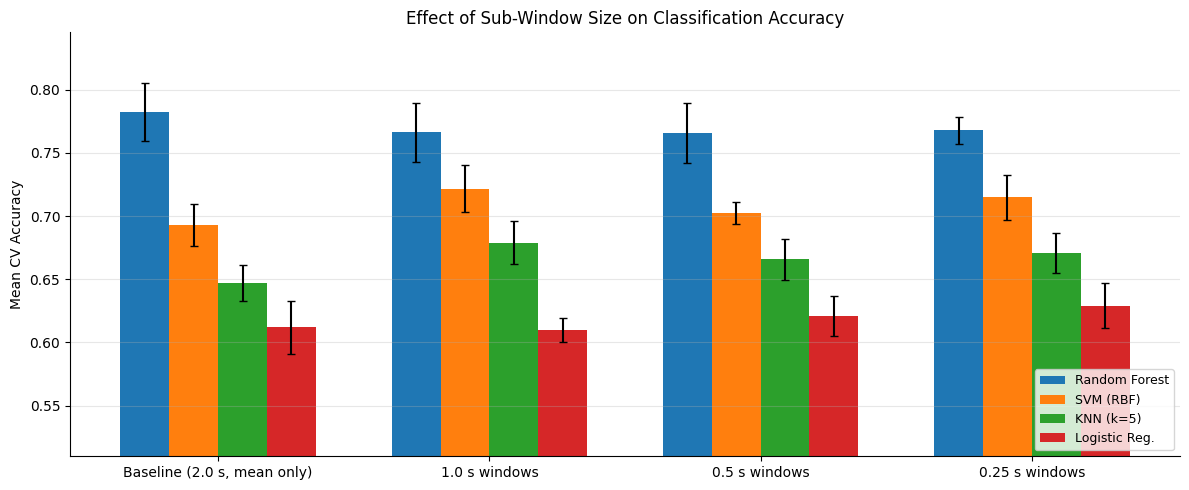

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

window_names = list(WINDOW_CONFIGS.keys())
model_names = list(MODELS.keys())
x = np.arange(len(window_names))
width = 0.18

for i, model_name in enumerate(model_names):
    means = [results_df[(results_df['Window'] == w) & (results_df['Model'] == model_name)]['Accuracy'].values[0]
             for w in window_names]
    stds  = [results_df[(results_df['Window'] == w) & (results_df['Model'] == model_name)]['Std'].values[0]
             for w in window_names]
    ax.bar(x + i * width, means, width, yerr=stds, label=model_name, capsize=3)

ax.set_xticks(x + width * (len(model_names) - 1) / 2)
ax.set_xticklabels(window_names)
ax.set_ylabel('Accuracy')
ax.set_title('Window Size vs Classification Accuracy')
ax.set_ylim(bottom=max(0, results_df['Accuracy'].min() - 0.1))
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Improvement over baseline

In [ ]:
baseline = results_df[results_df['Window'] == 'Baseline (2.0s)'].set_index('Model')['Accuracy']

for model_name in model_names:
    base = baseline[model_name]
    print(f'{model_name}:')
    for window_name in window_names[1:]:
        acc = results_df[(results_df['Window'] == window_name) & (results_df['Model'] == model_name)]['Accuracy'].values[0]
        delta = acc - base
        print(f'  {window_name:18s}  {acc:.4f}  ({delta:+.4f})')
    print()

Accuracy change vs baseline (positive = windowing helps):

  Random Forest:
    1.0 s windows              0.7663  (▼ -0.0161)
    0.5 s windows              0.7656  (▼ -0.0169)
    0.25 s windows             0.7678  (▼ -0.0147)

  SVM (RBF):
    1.0 s windows              0.7215  (▲ +0.0287)
    0.5 s windows              0.7024  (▲ +0.0095)
    0.25 s windows             0.7149  (▲ +0.0220)

  KNN (k=5):
    1.0 s windows              0.6789  (▲ +0.0316)
    0.5 s windows              0.6657  (▲ +0.0184)
    0.25 s windows             0.6708  (▲ +0.0235)

  Logistic Reg.:
    1.0 s windows              0.6098  (▼ -0.0022)
    0.5 s windows              0.6209  (▲ +0.0088)
    0.25 s windows             0.6290  (▲ +0.0169)



## 8. Best configuration

In [ ]:
best = results_df.loc[results_df['Accuracy'].idxmax()]
print(f'Best: {best["Model"]} + {best["Window"]} → {best["Accuracy"]:.4f} ± {best["Std"]:.4f}')

Best configuration:
  Window strategy : Baseline (2.0 s, mean only)
  Model           : Random Forest
  Mean CV Accuracy: 0.7825 ± 0.0228
  Per-fold scores : ['0.8132', '0.7831', '0.7610', '0.7537', '0.8015']


## 9. Heatmap

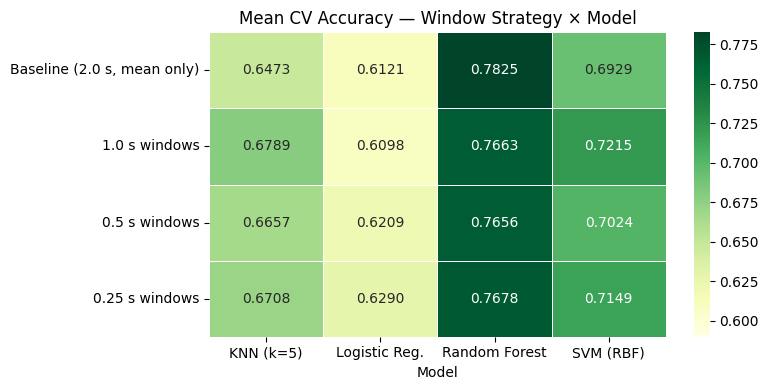

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlGn', ax=ax, linewidths=0.5)
ax.set_title('Accuracy: Window Strategy × Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## 10. Takeaway

- If windowed approaches beat the baseline → sub-windows capture temporal variation that mean-pooling over 2s washes out.
- If baseline matches or beats windowed → the chord signal is stationary enough that one window suffices.

---

# Part 2 — Neural Networks

| Model | Input |
|-------|-------|
| MLP | Flat chroma+MFCC features |
| CNN | 2D mel spectrogram |
| RNN (LSTM) | Mel spectrogram as sequence |

Spectrogram strategies: full 2s, averaged sub-windows, concatenated sub-windows.

In [ ]:
import keras
from src.models import build_mlp, build_cnn, build_rnn


def cv_evaluate_keras(build_fn, X, y_array, n_splits=5, epochs=60, batch_size=32):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    fold_accs = []

    for train_idx, val_idx in skf.split(X, y_array):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y_array[train_idx], y_array[val_idx]

        model = build_fn(X_train.shape[1:])
        model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                  validation_data=(X_val, y_val), verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)])

        _, acc = model.evaluate(X_val, y_val, verbose=0)
        fold_accs.append(acc)

    return fold_accs

Using device: cuda
Training utilities ready.


## 11. Build spectrogram datasets

In [ ]:
def pad_specs(specs):
    max_t = max(s.shape[1] for s in specs)
    padded = []
    for s in specs:
        if s.shape[1] < max_t:
            s = np.pad(s, ((0, 0), (0, max_t - s.shape[1])), mode='constant', constant_values=s.min())
        else:
            s = s[:, :max_t]
        padded.append(s)
    return np.array(padded)


def build_mel_full(waveforms, sr):
    specs = [extract_mel_spectrogram(y, sr) for y in waveforms]
    return pad_specs(specs)[..., np.newaxis]


def build_mel_windowed_avg(waveforms, sr, window_sec, overlap=0.5):
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    all_specs = []

    for y_wav in waveforms:
        win_specs = []
        start = 0
        while start + window_samples <= len(y_wav):
            mel = extract_mel_spectrogram(y_wav[start:start + window_samples], sr)
            win_specs.append(mel)
            start += hop_samples
        if not win_specs:
            win_specs.append(extract_mel_spectrogram(y_wav, sr))
        all_specs.append(np.mean(win_specs, axis=0))

    return pad_specs(all_specs)[..., np.newaxis]


def build_mel_windowed_concat(waveforms, sr, window_sec, overlap=0.5):
    window_samples = int(window_sec * sr)
    hop_samples = int(window_samples * (1 - overlap))
    all_specs = []

    for y_wav in waveforms:
        win_specs = []
        start = 0
        while start + window_samples <= len(y_wav):
            mel = extract_mel_spectrogram(y_wav[start:start + window_samples], sr)
            win_specs.append(mel)
            start += hop_samples
        if not win_specs:
            win_specs.append(extract_mel_spectrogram(y_wav, sr))
        all_specs.append(np.concatenate(win_specs, axis=1))

    return pad_specs(all_specs)[..., np.newaxis]


print('Building spectrograms...')
spec_datasets = {}

spec_datasets['Full 2.0s'] = build_mel_full(waveforms, SR)
spec_datasets['Avg 0.5s'] = build_mel_windowed_avg(waveforms, SR, 0.5)
spec_datasets['Avg 0.25s'] = build_mel_windowed_avg(waveforms, SR, 0.25)
spec_datasets['Concat 0.5s'] = build_mel_windowed_concat(waveforms, SR, 0.5)

for name, data in spec_datasets.items():
    print(f'  {name}: {data.shape}')

Building spectrogram datasets...
  Full 2.0 s:             torch.Size([1361, 1, 128, 87])
  Avg 0.5 s windows:      torch.Size([1361, 1, 128, 22])
  Avg 0.25 s windows:     torch.Size([1361, 1, 128, 11])
  Concat 0.5 s windows:   torch.Size([1361, 1, 128, 154])

All spectrogram datasets built.


## 12. MLP experiment

In [ ]:
nn_results = []

print('MLP\n')
for window_name, X_np in feature_sets.items():
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_np)

    fold_accs = cv_evaluate_keras(
        lambda shape: build_mlp(shape[0]),
        X_scaled, y, epochs=80
    )
    mean_acc, std_acc = np.mean(fold_accs), np.std(fold_accs)
    nn_results.append({'Model': 'MLP', 'Data': window_name, 'Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs})
    print(f'  {window_name:20s} | {mean_acc:.4f} ± {std_acc:.4f}')

=== MLP experiments ===

  MLP | Baseline (2.0 s, mean only)      | acc = 0.6767 ± 0.0384
  MLP | 1.0 s windows                    | acc = 0.7480 ± 0.0242
  MLP | 0.5 s windows                    | acc = 0.7369 ± 0.0089
  MLP | 0.25 s windows                   | acc = 0.7509 ± 0.0154

MLP experiments done.


## 13. CNN experiment

In [ ]:
print('CNN\n')
for spec_name, X in spec_datasets.items():
    fold_accs = cv_evaluate_keras(build_cnn, X, y, epochs=80)
    mean_acc, std_acc = np.mean(fold_accs), np.std(fold_accs)
    nn_results.append({'Model': 'CNN', 'Data': spec_name, 'Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs})
    print(f'  {spec_name:20s} | {mean_acc:.4f} ± {std_acc:.4f}')

=== CNN experiments ===

  CNN | Full 2.0 s                     | acc = 0.7486 ± 0.0917
  CNN | Avg 0.5 s windows              | acc = 0.8104 ± 0.0645
  CNN | Avg 0.25 s windows             | acc = 0.6729 ± 0.1465
  CNN | Concat 0.5 s windows           | acc = 0.7905 ± 0.0964

CNN experiments done.


## 14. RNN (LSTM) experiment

In [ ]:
print('LSTM\n')
for spec_name, X in spec_datasets.items():
    X_seq = X.squeeze(-1).transpose(0, 2, 1)
    fold_accs = cv_evaluate_keras(build_rnn, X_seq, y, epochs=80)
    mean_acc, std_acc = np.mean(fold_accs), np.std(fold_accs)
    nn_results.append({'Model': 'LSTM', 'Data': spec_name, 'Accuracy': mean_acc, 'Std': std_acc, 'Folds': fold_accs})
    print(f'  {spec_name:20s} | {mean_acc:.4f} ± {std_acc:.4f}')

=== LSTM experiments ===

  LSTM | Full 2.0 s                     | acc = 0.6340 ± 0.0389
  LSTM | Avg 0.5 s windows              | acc = 0.6112 ± 0.0910
  LSTM | Avg 0.25 s windows             | acc = 0.6083 ± 0.0830
  LSTM | Concat 0.5 s windows           | acc = 0.6245 ± 0.0106

=== GRU experiments ===

  GRU  | Full 2.0 s                     | acc = 0.6465 ± 0.0587
  GRU  | Avg 0.5 s windows              | acc = 0.5834 ± 0.0612
  GRU  | Avg 0.25 s windows             | acc = 0.6502 ± 0.1021
  GRU  | Concat 0.5 s windows           | acc = 0.6480 ± 0.0517

All RNN experiments done.


## 15. NN results

In [ ]:
nn_results_df = pd.DataFrame(nn_results)

nn_pivot = nn_results_df.pivot_table(index='Data', columns='Model', values='Accuracy')
mlp_rows = list(WINDOW_CONFIGS.keys())
spec_rows = list(spec_datasets.keys())
all_rows = mlp_rows + [r for r in spec_rows if r not in mlp_rows]
nn_pivot = nn_pivot.reindex([r for r in all_rows if r in nn_pivot.index])

display(nn_pivot.style.format('{:.4f}').background_gradient(cmap='YlOrRd', axis=None))

Model,CNN,GRU,LSTM,MLP
Data Strategy,,,,
"Baseline (2.0 s, mean only)",nan,nan,nan,0.6767
1.0 s windows,nan,nan,nan,0.7480
0.5 s windows,nan,nan,nan,0.7369
0.25 s windows,nan,nan,nan,0.7509
Full 2.0 s,0.7486,0.6465,0.6340,nan
Avg 0.5 s windows,0.8104,0.5834,0.6112,nan
Avg 0.25 s windows,0.6729,0.6502,0.6083,nan
Concat 0.5 s windows,0.7905,0.6480,0.6245,nan


## 16. NN accuracy chart

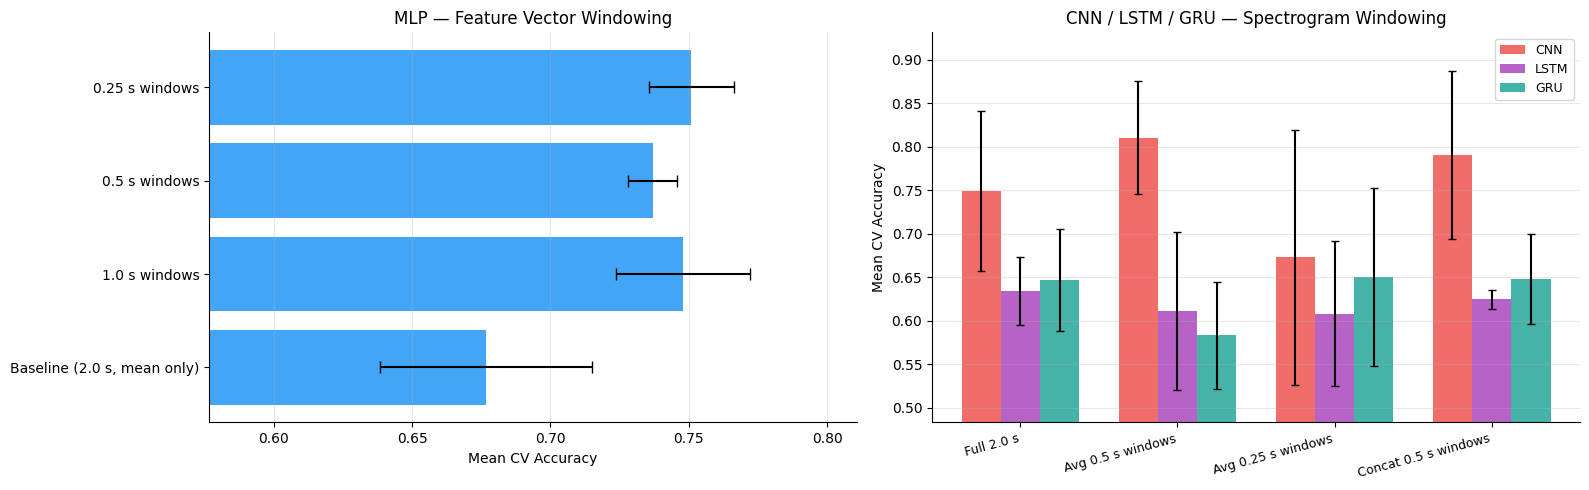

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mlp_df = nn_results_df[nn_results_df['Model'] == 'MLP']
ax = axes[0]
ax.barh(mlp_df['Data'], mlp_df['Accuracy'], xerr=mlp_df['Std'], color='#42a5f5', capsize=4)
ax.set_xlabel('Accuracy')
ax.set_title('MLP — Feature Windowing')
ax.set_xlim(left=max(0, mlp_df['Accuracy'].min() - 0.1))
ax.spines[['top', 'right']].set_visible(False)

spec_df = nn_results_df[nn_results_df['Model'] != 'MLP']
ax = axes[1]
spec_strats = list(spec_datasets.keys())
nn_models = ['CNN', 'LSTM']
x = np.arange(len(spec_strats))
width = 0.3

for i, m_name in enumerate(nn_models):
    subset = spec_df[spec_df['Model'] == m_name]
    means = [subset[subset['Data'] == s]['Accuracy'].values[0] if len(subset[subset['Data'] == s]) > 0 else 0 for s in spec_strats]
    stds = [subset[subset['Data'] == s]['Std'].values[0] if len(subset[subset['Data'] == s]) > 0 else 0 for s in spec_strats]
    ax.bar(x + i * width, means, width, yerr=stds, label=m_name, capsize=3)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(spec_strats, rotation=15, ha='right')
ax.set_ylabel('Accuracy')
ax.set_title('CNN / LSTM — Spectrogram Windowing')
ax.set_ylim(bottom=max(0, spec_df['Accuracy'].min() - 0.1))
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 17. NN heatmap

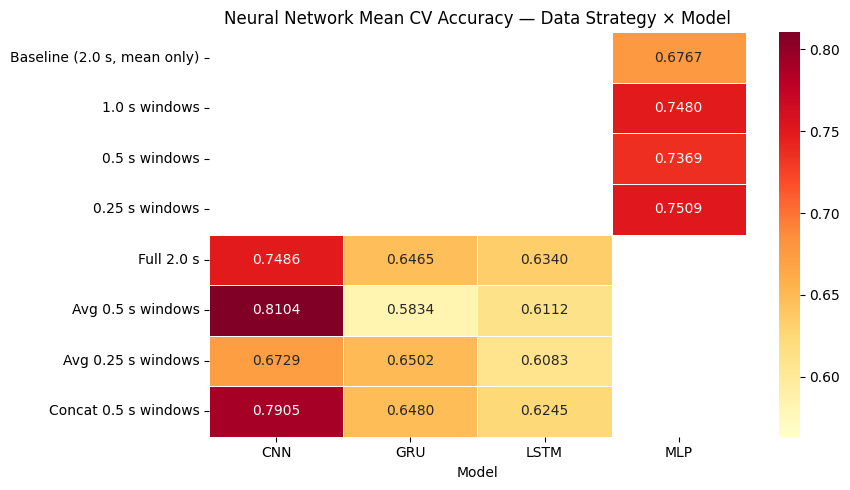

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(nn_pivot, annot=True, fmt='.4f', cmap='YlOrRd', ax=ax, linewidths=0.5)
ax.set_title('NN Accuracy: Data Strategy × Model')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## 18. Grand comparison — all models

In [ ]:
sklearn_df = results_df.rename(columns={'Window': 'Data'})
all_results_df = pd.concat([sklearn_df, nn_results_df], ignore_index=True)

best_overall = all_results_df.loc[all_results_df['Accuracy'].idxmax()]
print(f'Best: {best_overall["Model"]} + {best_overall["Data"]} → {best_overall["Accuracy"]:.4f} ± {best_overall["Std"]:.4f}')
print()

top10 = all_results_df.nlargest(10, 'Accuracy')[['Model', 'Data', 'Accuracy', 'Std']]
display(top10.style.format({'Accuracy': '{:.4f}', 'Std': '{:.4f}'}).background_gradient(subset=['Accuracy'], cmap='YlGn'))

BEST OVERALL CONFIGURATION
  Model          : CNN
  Data Strategy  : Avg 0.5 s windows
  Mean CV Accuracy: 0.8104 ± 0.0645
  Per-fold scores : ['0.8681', '0.7904', '0.8676', '0.6949', '0.8309']

Top 10 configurations:



,Model,Data Strategy,Mean Accuracy,Std
21,CNN,Avg 0.5 s windows,0.8104,0.0645
23,CNN,Concat 0.5 s windows,0.7905,0.0964
0,Random Forest,"Baseline (2.0 s, mean only)",0.7825,0.0228
12,Random Forest,0.25 s windows,0.7678,0.0106
4,Random Forest,1.0 s windows,0.7663,0.0235
8,Random Forest,0.5 s windows,0.7656,0.0238
19,MLP,0.25 s windows,0.7509,0.0154
20,CNN,Full 2.0 s,0.7486,0.0917
17,MLP,1.0 s windows,0.7480,0.0242
18,MLP,0.5 s windows,0.7369,0.0089


## 19. Grand heatmap

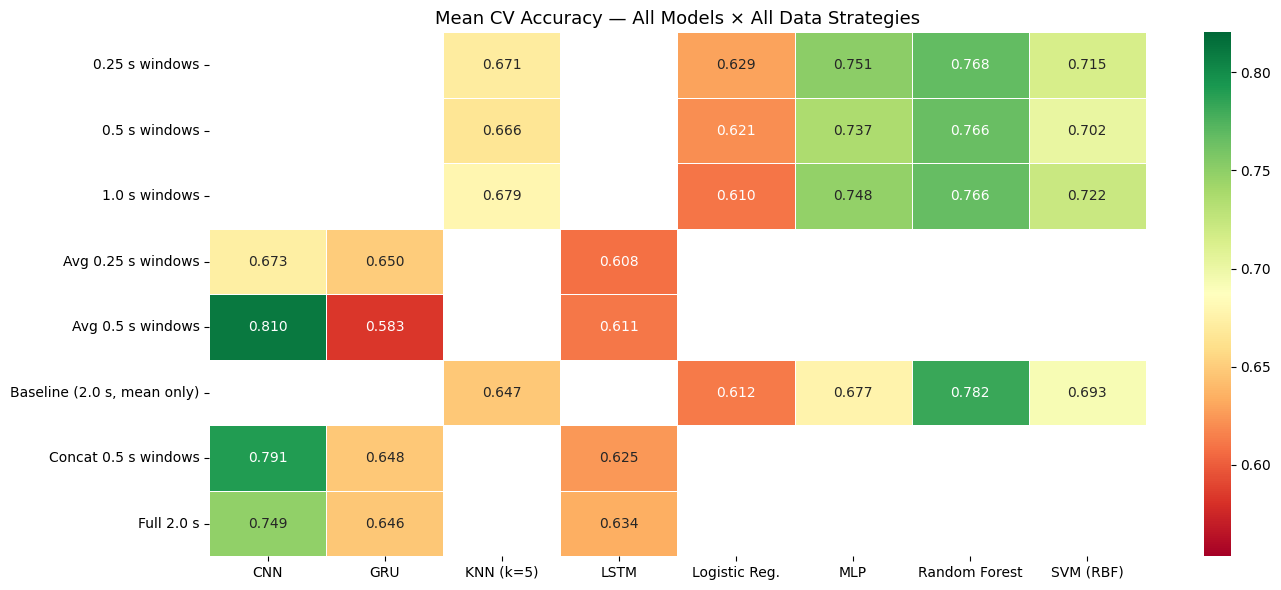

In [ ]:
grand_pivot = all_results_df.pivot_table(index='Data', columns='Model', values='Accuracy')

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(grand_pivot, annot=True, fmt='.3f', cmap='RdYlGn', ax=ax, linewidths=0.5)
ax.set_title('All Models × All Strategies')
ax.set_ylabel('')
fig.tight_layout()
plt.show()

## 20. Conclusion

The grand heatmap shows which model + data strategy combination works best. Use the top result to pick both the architecture and the preprocessing pipeline.